# ML LAB5 : Feature Selection (filter and wrapper methods)

SACI Zhour - AI2

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif,
                                       mutual_info_classif, SequentialFeatureSelector,
                                       RFE, RFECV)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
SEED = 42
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
sns.set_theme(style="whitegrid")

## Part A. Data inspection and baseline

### 1 - Dataset 

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame
X, y = df.drop(columns="target"), df["target"]

print("Shape:", df.shape)
print(df.dtypes.value_counts())
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
df.describe().T.head(10)

Shape: (569, 31)
float64    30
int64       1
Name: count, dtype: int64
Missing values: 0
Duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


### 2 - target distribution

target
1    357
0    212
Name: count, dtype: int64 
 target
1    0.627
0    0.373
Name: proportion, dtype: float64


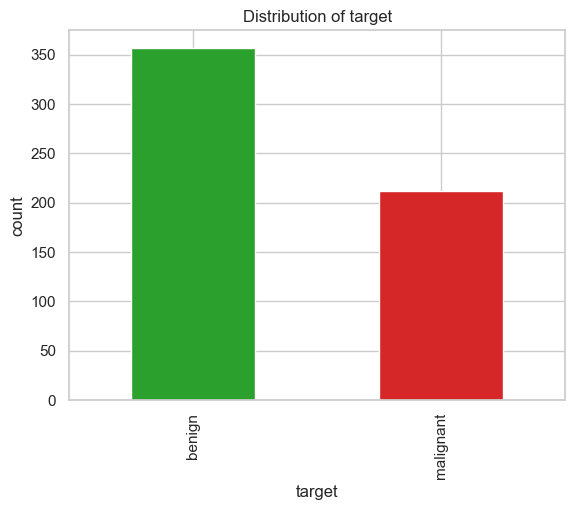

In [3]:
print(y.value_counts(), "\n", y.value_counts(normalize=True).round(3))
y.map({0: "malignant", 1: "benign"}).value_counts().plot(kind="bar", color=["tab:green", "tab:red"])
plt.title("Distribution of target"); plt.ylabel("count"); plt.show()

### 3 - split data

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)

scaler = StandardScaler().fit(Xtr)                      # fitted on train only
Xtr_s = pd.DataFrame(scaler.transform(Xtr), columns=X.columns, index=Xtr.index)
Xte_s = pd.DataFrame(scaler.transform(Xte), columns=X.columns, index=Xte.index)

dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
dummy_acc = accuracy_score(yte, dummy.predict(Xte))
print(f"Dummy (most_frequent) test accuracy: {dummy_acc:.4f}")

Dummy (most_frequent) test accuracy: 0.6257


### 4 - baseline model with all 30 features

In [6]:
def evaluate(pipe, Xtr, ytr, Xte, yte):
    t0 = time.perf_counter()
    pipe.fit(Xtr, ytr)
    t = time.perf_counter() - t0
    ptr, pte = pipe.predict(Xtr), pipe.predict(Xte)
    return dict(train_acc=accuracy_score(ytr, ptr), test_acc=accuracy_score(yte, pte),
                train_f1=f1_score(ytr, ptr), test_f1=f1_score(yte, pte), time_s=t)

base_pipe = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])
res = evaluate(base_pipe, Xtr, ytr, Xte, yte)
baseline = pd.DataFrame([{"Method": "Baseline (all)", "Nb features": 30, **res}]).round(4)
baseline

,Method,Nb features,train_acc,test_acc,train_f1,test_f1,time_s
0,Baseline (all),30,0.9874,0.9883,0.9901,0.9907,0.0868


### 5 - correlation heatmap

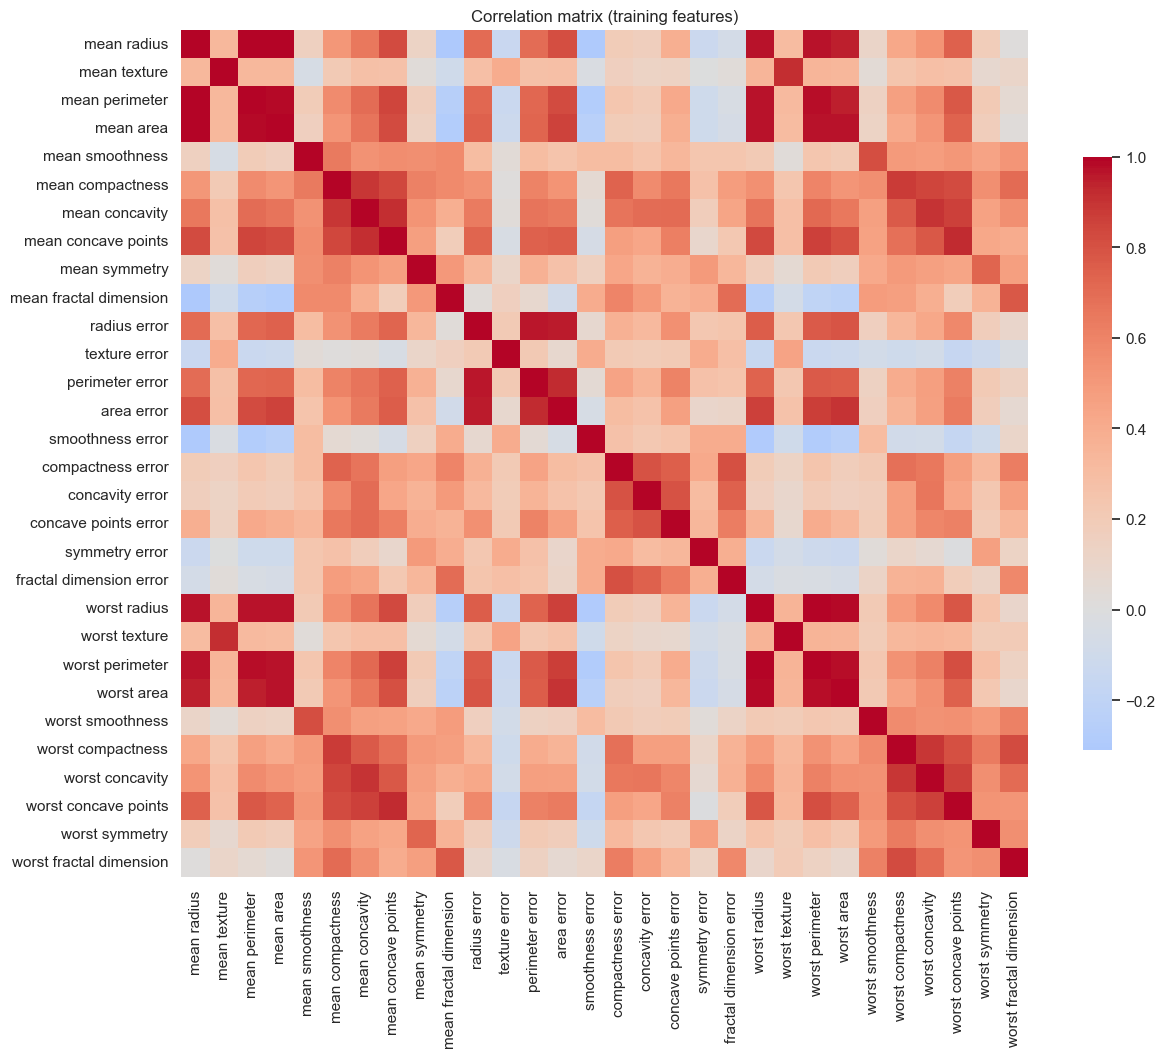

             f1              f2     corr
    mean radius  mean perimeter 0.997803
   worst radius worst perimeter 0.993442
    mean radius       mean area 0.990629
 mean perimeter       mean area 0.989496
   worst radius      worst area 0.986020
worst perimeter      worst area 0.978478
 mean perimeter worst perimeter 0.974864
      mean area    worst radius 0.974024
    mean radius    worst radius 0.974018
 mean perimeter    worst radius 0.973627
      mean area worst perimeter 0.970334
    mean radius worst perimeter 0.969837
      mean area      worst area 0.964368
   radius error perimeter error 0.960326
   radius error      area error 0.954404


In [7]:
corr = Xtr.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation matrix (training features)"); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
             .rename("corr").reset_index())
pairs.columns = ["f1", "f2", "corr"]
print(pairs[pairs["corr"].abs() > 0.95].sort_values("corr", ascending=False).to_string(index=False))

**Why this dataset is a good candidate for feature selection:**
- Strong redundancy: radius / perimeter / area (mean and worst) have |r| > 0.95, so many features carry the same information.
- 30 features for only 398 training samples, so there is a real risk of overfitting and of unstable coefficients.
- Interpretability: a clinician prefers a model based on a handful of measurements.

## Part B : Filter methods

### B.1 Variance threshold

In [9]:
var = Xtr.var().sort_values()
print(var.head(8))

rows = []
for thr in [0, 0.01, 0.1]:
    vt = VarianceThreshold(thr).fit(Xtr)
    removed = list(Xtr.columns[~vt.get_support()])
    rows.append({"threshold": thr, "n_removed": len(removed), "removed": removed})
pd.DataFrame(rows)

fractal dimension error    0.000008
smoothness error           0.000009
concave points error       0.000040
mean fractal dimension     0.000053
symmetry error             0.000077
mean smoothness            0.000178
compactness error          0.000350
worst fractal dimension    0.000363
dtype: float64


,threshold,n_removed,removed
0,0.00,0,[]
1,0.01,16,"[mean smoothness, mean compactness, mean conca..."
2,0.10,19,"[mean smoothness, mean compactness, mean conca..."


- After standardization every variance equals 1, so every feature passes or fails together and the filter does nothing.
- Variance depends on the units/scale of each variable (area is about 1e5, fractal dimension about 1e-5). A low variance here says nothing about usefulness, and no feature is constant, so the filter is of limited use.

### B.2 Removing correlated features

In [10]:
def remove_correlated(X, y, threshold):
    c = X.corr().abs()
    ty = X.apply(lambda col: abs(np.corrcoef(col, y)[0, 1]))
    keep = list(X.columns)
    for i, a in enumerate(X.columns):
        for b in X.columns[i + 1:]:
            if a in keep and b in keep and c.loc[a, b] > threshold:
                keep.remove(a if ty[a] < ty[b] else b)
    return keep

rows = []
for thr in [0.95, 0.90, 0.80]:
    kept = remove_correlated(Xtr, ytr, thr)
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])
    cv_acc = cross_val_score(pipe, Xtr[kept], ytr, cv=cv).mean()
    r = evaluate(pipe, Xtr[kept], ytr, Xte[kept], yte)
    rows.append({"threshold": thr, "n_kept": len(kept), "cv_acc": cv_acc, "test_acc": r["test_acc"]})
b2 = pd.DataFrame(rows).round(4); b2

,threshold,n_kept,cv_acc,test_acc
0,0.95,23,0.9824,0.9825
1,0.90,19,0.9698,0.9708
2,0.80,13,0.9422,0.9415


removing redundancy reduces the number of features (and instability) but does not by itself raise accuracy: the removal is blind to relevance except through the tie-break. Compare `test_acc` with the baseline.

### B.3 Univariate scores and SelectKBest

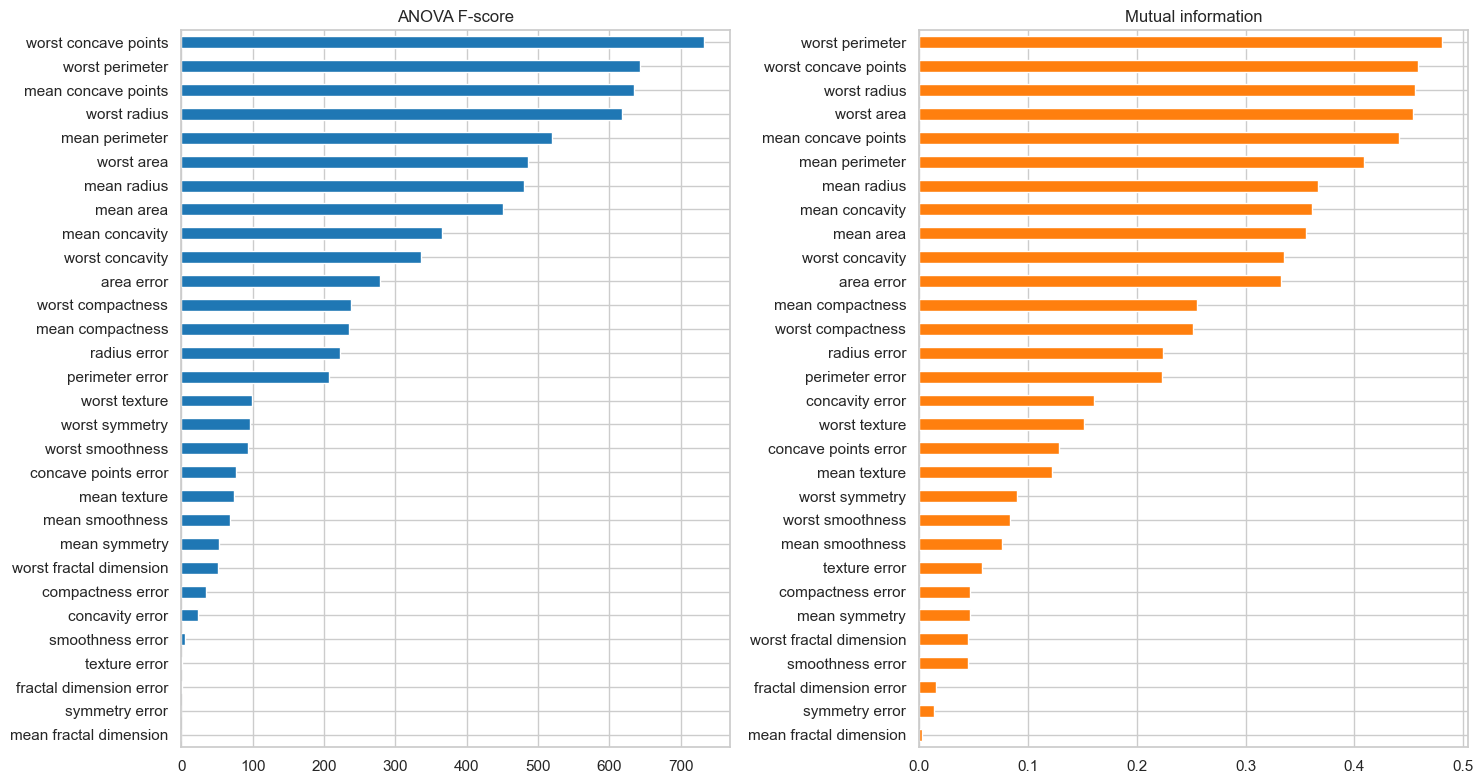

Spearman correlation between the two rankings: 0.966


In [11]:
F, p = f_classif(Xtr, ytr)
MI = mutual_info_classif(Xtr, ytr, random_state=SEED)
scores = pd.DataFrame({"F": F, "p_value": p, "MI": MI}, index=X.columns)

fig, ax = plt.subplots(1, 2, figsize=(15, 8))
scores["F"].sort_values().plot.barh(ax=ax[0], color="tab:blue"); ax[0].set_title("ANOVA F-score")
scores["MI"].sort_values().plot.barh(ax=ax[1], color="tab:orange"); ax[1].set_title("Mutual information")
plt.tight_layout(); plt.show()

rho, _ = spearmanr(scores["F"], scores["MI"])
print(f"Spearman correlation between the two rankings: {rho:.3f}")

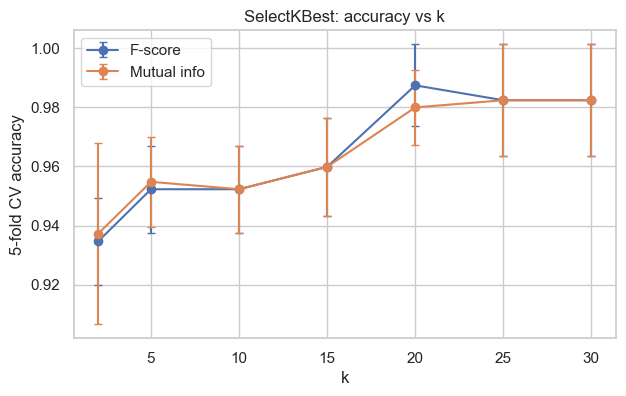

Chosen k (smallest within 1 std of best): {'F-score': 20, 'Mutual info': 20}


In [12]:
ks = [2, 5, 10, 15, 20, 25, 30]
score_funcs = {"F-score": f_classif,
               "Mutual info": lambda X_, y_: mutual_info_classif(X_, y_, random_state=SEED)}

kb = {}
for name, fn in score_funcs.items():
    kb[name] = []
    for k in ks:
        pipe = Pipeline([("scaler", StandardScaler()), ("sel", SelectKBest(fn, k=k)),
                         ("clf", LogisticRegression(max_iter=1000))])
        s = cross_val_score(pipe, Xtr, ytr, cv=cv)
        kb[name].append((s.mean(), s.std()))

plt.figure(figsize=(7, 4))
best_k = {}
for name, vals in kb.items():
    m = np.array([v[0] for v in vals]); sd = np.array([v[1] for v in vals])
    plt.errorbar(ks, m, yerr=sd, marker="o", capsize=3, label=name)
    i = m.argmax()
    best_k[name] = min(k for k, mm in zip(ks, m) if mm >= m[i] - sd[i])   # 1-std rule
plt.xlabel("k"); plt.ylabel("5-fold CV accuracy"); plt.legend(); plt.title("SelectKBest: accuracy vs k"); plt.show()
print("Chosen k (smallest within 1 std of best):", best_k)

a univariate filter scores each feature alone, so radius, perimeter and area (nearly identical) all get high scores and are all selected, which wastes the budget k on redundant information. It cannot see interactions or redundancy between features.

## Part C : Wrapper methods

### C.1 Forward selection

sklearn forward: ['mean radius', 'mean texture', 'mean perimeter', 'mean compactness', 'texture error', 'smoothness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness']
own forward:    ['worst radius', 'worst smoothness', 'worst texture', 'mean radius'] (4.8s)


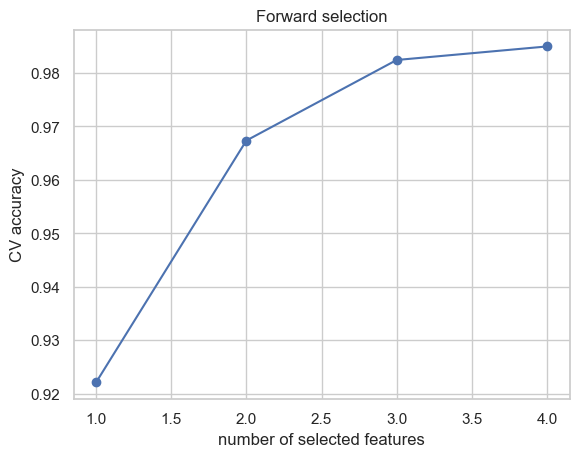

Same set as sklearn: False | difference: {'mean perimeter', 'smoothness error', 'texture error', 'mean compactness', 'mean texture', 'worst perimeter'}


In [14]:
lr = LogisticRegression(max_iter=1000)

# 1 - scikit-learn
sfs_f = SequentialFeatureSelector(lr, n_features_to_select=10, direction="forward",
                                  scoring="accuracy", cv=cv, n_jobs=-1).fit(Xtr_s, ytr)
fwd_sk = list(Xtr_s.columns[sfs_f.get_support()])
print("sklearn forward:", fwd_sk)

# 2 - own implementation
def forward_selection(X, y, max_k=10, eps=0.001):
    selected, history, best_prev = [], [], 0.0
    while len(selected) < max_k:
        cand = {f: cross_val_score(lr, X[selected + [f]], y, cv=cv).mean()
                for f in X.columns if f not in selected}
        f_best = max(cand, key=cand.get)
        if cand[f_best] - best_prev < eps and selected:      # stop when gain < epsilon
            break
        selected.append(f_best); best_prev = cand[f_best]
        history.append(best_prev)
    return selected, history

t0 = time.perf_counter()
fwd_own, fwd_hist = forward_selection(Xtr_s, ytr)
t_fwd_own = time.perf_counter() - t0
print("own forward:   ", fwd_own, f"({t_fwd_own:.1f}s)")

# 3 - plot and comparison
plt.plot(range(1, len(fwd_hist) + 1), fwd_hist, marker="o")
plt.xlabel("number of selected features"); plt.ylabel("CV accuracy"); plt.title("Forward selection"); plt.show()
print("Same set as sklearn:", set(fwd_own) == set(fwd_sk), "| difference:", set(fwd_own) ^ set(fwd_sk))

My implementation does not select the same features as scikit-learn (`Same set as sklearn: False`). The reason is the stopping rule: my loop stops at 4 features (`worst radius`, `worst smoothness`, `worst texture`, `mean radius`) because the 5th feature gives a gain below ε = 0.001, while scikit-learn always continues until 10 features. The CV accuracy is already about 0.985 at 4 features and the curve is almost flat after the 3rd, so the extra 6 features add little on the training CV. Both versions start from the same greedy logic, so the 4 features of mine should also be among the first ones chosen by scikit-learn. Check this in your output: `worst radius`, `worst smoothness`, `worst texture` and `mean radius` all appear in the scikit-learn list on your screenshot.

### C.2 Backward elimination

sklearn backward: ['texture error', 'area error', 'smoothness error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst concavity', 'worst symmetry']
own backward (10): ['texture error', 'area error', 'smoothness error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst concavity', 'worst symmetry'] (17.0s)


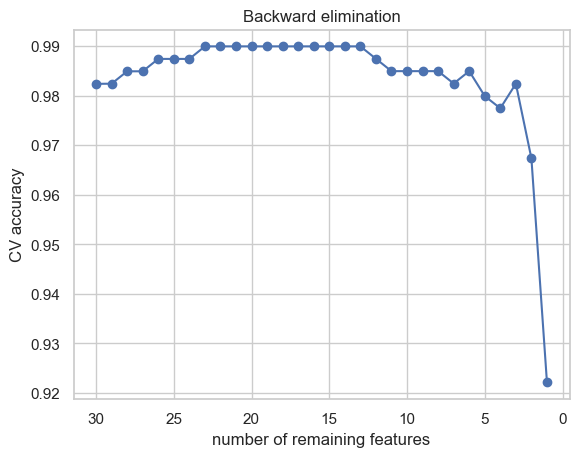

Forward ∩ Backward: ['worst radius', 'worst smoothness', 'worst texture']
Forward only: ['mean radius']
Backward only: ['area error', 'fractal dimension error', 'smoothness error', 'texture error', 'worst concavity', 'worst perimeter', 'worst symmetry']


In [15]:
sfs_b = SequentialFeatureSelector(lr, n_features_to_select=10, direction="backward",
                                  scoring="accuracy", cv=cv, n_jobs=-1).fit(Xtr_s, ytr)
bwd_sk = list(Xtr_s.columns[sfs_b.get_support()])
print("sklearn backward:", bwd_sk)

def backward_elimination(X, y, min_k=1):
    remaining, history = list(X.columns), {}
    history[len(remaining)] = cross_val_score(lr, X[remaining], y, cv=cv).mean()
    sets = {len(remaining): list(remaining)}
    while len(remaining) > min_k:
        cand = {f: cross_val_score(lr, X[[c for c in remaining if c != f]], y, cv=cv).mean()
                for f in remaining}
        f_drop = max(cand, key=cand.get)                     # least degradation
        remaining.remove(f_drop)
        history[len(remaining)] = cand[f_drop]; sets[len(remaining)] = list(remaining)
    return sets, history

t0 = time.perf_counter()
bwd_sets, bwd_hist = backward_elimination(Xtr_s, ytr)
t_bwd_own = time.perf_counter() - t0
bwd_own = bwd_sets[10]
print("own backward (10):", bwd_own, f"({t_bwd_own:.1f}s)")

plt.plot(list(bwd_hist.keys()), list(bwd_hist.values()), marker="o")
plt.gca().invert_xaxis(); plt.xlabel("number of remaining features"); plt.ylabel("CV accuracy")
plt.title("Backward elimination"); plt.show()

print("Forward ∩ Backward:", sorted(set(fwd_own) & set(bwd_own)))
print("Forward only:", sorted(set(fwd_own) - set(bwd_own)))
print("Backward only:", sorted(set(bwd_own) - set(fwd_own)))

the two searches explore different paths. Forward builds up and picks features that are good *alone*, while backward starts from the full set and keeps features that are useful *in the presence of the others*. With correlated features (radius / perimeter / area), which one survives depends on the path, so the sets differ.

### C.3 Recursive feature elimination (RFE)

                      support  ranking
worst smoothness         True        1
worst perimeter          True        1
worst texture            True        1
mean area                True        1
worst radius             True        1
worst symmetry           True        1
mean concave points      True        1
worst concave points     True        1
area error               True        1
worst area               True        1
mean compactness        False        2
mean radius             False        3
radius error            False        4
worst concavity         False        5
compactness error       False        6


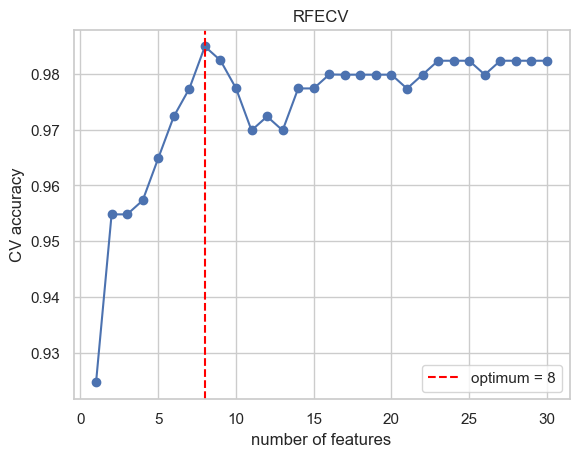

Optimal number: 8


In [16]:
# 1 - RFE with logistic regression
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=10).fit(Xtr_s, ytr)
rfe_lr = list(Xtr_s.columns[rfe.support_])
print(pd.DataFrame({"support": rfe.support_, "ranking": rfe.ranking_}, index=Xtr_s.columns)
        .sort_values("ranking").head(15))

# 2 - RFECV
rfecv = RFECV(LogisticRegression(max_iter=1000), step=1, cv=cv, scoring="accuracy").fit(Xtr_s, ytr)
n_opt = rfecv.n_features_
means = rfecv.cv_results_["mean_test_score"]
plt.plot(range(1, len(means) + 1), means, marker="o")
plt.axvline(n_opt, color="red", ls="--", label=f"optimum = {n_opt}")
plt.xlabel("number of features"); plt.ylabel("CV accuracy"); plt.legend(); plt.title("RFECV"); plt.show()
rfecv_feats = list(Xtr_s.columns[rfecv.support_])
print("Optimal number:", n_opt)

In [17]:
rfe_svc = RFE(SVC(kernel="linear"), n_features_to_select=10).fit(Xtr_s, ytr)
rfe_rf = RFE(RandomForestClassifier(random_state=SEED), n_features_to_select=10).fit(Xtr_s, ytr)
sets = {"RFE-LR": set(rfe_lr),
        "RFE-SVC": set(Xtr_s.columns[rfe_svc.support_]),
        "RFE-RF": set(Xtr_s.columns[rfe_rf.support_])}
print("LR ∩ SVC:", len(sets["RFE-LR"] & sets["RFE-SVC"]), "| LR ∩ RF:", len(sets["RFE-LR"] & sets["RFE-RF"]))
sets

LR ∩ SVC: 8 | LR ∩ RF: 6


{'RFE-LR': {'area error',
  'mean area',
  'mean concave points',
  'worst area',
  'worst concave points',
  'worst perimeter',
  'worst radius',
  'worst smoothness',
  'worst symmetry',
  'worst texture'},
 'RFE-SVC': {'area error',
  'worst area',
  'worst compactness',
  'worst concave points',
  'worst concavity',
  'worst perimeter',
  'worst radius',
  'worst smoothness',
  'worst symmetry',
  'worst texture'},
 'RFE-RF': {'mean area',
  'mean concave points',
  'mean concavity',
  'mean perimeter',
  'mean radius',
  'worst area',
  'worst concave points',
  'worst concavity',
  'worst perimeter',
  'worst radius'}}

- LR and linear SVC are both linear models, so their coefficients give similar rankings and the sets overlap strongly. Random forest ranks by impurity-based importance, which is nonlinear and favors other features, so its set differs more. **RFE is model-dependent.**
- **RFE vs Backward Elimination:** RFE removes the feature with the smallest |coefficient| (or importance) after *one* training per step, so it trains about p − k models in total. Backward Elimination removes the feature whose removal hurts the CV score the least, which needs a CV evaluation of every candidate removal at every step (about 5·Σ(i) models). RFE is much cheaper but its criterion is only a proxy.

### C.4 Cost of the wrapper search

In [18]:
p, k, folds = 30, 10, 5
n_fwd = sum(p - i for i in range(k)) * folds
n_exh = (2 ** p - 1) * folds
print(f"Forward selection (k={k}): {n_fwd} models")
print(f"Exhaustive search: {n_exh:,} models")

# verify with measured time: cost of one cross-validated evaluation
t0 = time.perf_counter(); cross_val_score(lr, Xtr_s.iloc[:, :10], ytr, cv=cv); t_cv = time.perf_counter() - t0
print(f"1 CV evaluation = {t_cv*1000:.1f} ms -> predicted forward time ≈ {sum(p-i for i in range(k))*t_cv:.1f}s "
      f"(measured {t_fwd_own:.1f}s)")
print(f"Exhaustive would take ≈ {(2**p-1)*t_cv/3600/24/365:.1f} years")

Forward selection (k=10): 1275 models
Exhaustive search: 5,368,709,115 models
1 CV evaluation = 32.1 ms -> predicted forward time ≈ 8.2s (measured 4.8s)
Exhaustive would take ≈ 1.1 years


Forward selection of k features among p: 5·Σ_{i=0}^{k−1}(p−i) = 5·(pk − k(k−1)/2) = 1275 models here, against 5·(2³⁰−1) ≈ 5.4·10⁹ for the exhaustive search.
The measured time should match the prediction (up to the early stop by ε and the varying subset size).

# Part D : Noise injection, leakage and final comparison

### D.1 Can the methods find the noise?

In [19]:
rng = np.random.default_rng(SEED)
noise_cols = [f"noise_{i:02d}" for i in range(20)]
Xtr50 = pd.concat([Xtr, pd.DataFrame(rng.standard_normal((len(Xtr), 20)), columns=noise_cols, index=Xtr.index)], axis=1)
Xte50 = pd.concat([Xte, pd.DataFrame(rng.standard_normal((len(Xte), 20)), columns=noise_cols, index=Xte.index)], axis=1)
print(Xtr50.shape, Xte50.shape)

def make_pipe(selector):
    return Pipeline([("scaler", StandardScaler()), ("sel", selector),
                     ("clf", LogisticRegression(max_iter=1000))])

methods50 = {
    "SelectKBest (F)": SelectKBest(f_classif, k=10),
    "Forward":  SequentialFeatureSelector(LogisticRegression(max_iter=1000), n_features_to_select=10,
                                          direction="forward", cv=cv, n_jobs=-1),
    "Backward": SequentialFeatureSelector(LogisticRegression(max_iter=1000), n_features_to_select=10,
                                          direction="backward", cv=cv, n_jobs=-1),
    "RFE": RFE(LogisticRegression(max_iter=1000), n_features_to_select=10),
}
rows = []
for name, sel in methods50.items():
    pipe = make_pipe(sel).fit(Xtr50, ytr)
    chosen = list(Xtr50.columns[pipe.named_steps["sel"].get_support()])
    rows.append({"Method": name, "n_noise_selected": sum(c.startswith("noise") for c in chosen),
                 "test_acc": accuracy_score(yte, pipe.predict(Xte50))})
pd.DataFrame(rows)

(398, 50) (171, 50)


,Method,n_noise_selected,test_acc
0,SelectKBest (F),0,0.935673
1,Forward,0,0.935673
2,Backward,5,0.959064
3,RFE,0,0.970760


- **Results (20 noise features added, 50 features in total, 10 kept by each method):**
  - SelectKBest (F-score): 0 noise features, test accuracy 0.936
  - Forward Selection: 0 noise features, test accuracy 0.936
  - Backward Elimination: **5 noise features**, test accuracy 0.959
  - RFE: 0 noise features, test accuracy 0.971
- **Most robust methods:** SelectKBest (F-score), Forward Selection and RFE found no noise feature.
  - **SelectKBest:** it ranks each feature against the target, so noise features get very low F-scores and are never chosen.
  - **Forward Selection:** it starts from an empty set, and a noise feature never gave a better CV accuracy than a real one.
  - **RFE:** the coefficients of the logistic regression on noise features are small, so these features are eliminated first.
- **Method fooled:** Backward Elimination selected 5 noise features.
  - It optimizes the CV accuracy starting from all 50 features.
  - The real features are strongly redundant (radius / perimeter / area), so removing one of them costs almost nothing.
  - A noise feature can then survive because of a small *chance* difference on a few folds.
- **Family most likely to be fooled:** the wrapper family.
  - It selects by a noisy CV score, which is a selection-bias / overfitting-to-the-CV effect.
  - The more candidates are tested (50 instead of 30), the more likely it is.
  - The filter does not depend on a model's CV score, so it is not fooled by chance gains.
- **Test accuracy is not a reliable measure here:** the gaps between methods are only a few patients out of 171 (one patient is 0.58 points). The number of noise features selected is the right measure of robustness.
- **Limit:** this is one seed and one split, so the ranking of the wrapper methods could change with another seed.

### D.2 Leakage in feature selection 

In [20]:
# Incorrect: selection on the whole training set, then CV on the reduced matrix
sel = SelectKBest(f_classif, k=10).fit(StandardScaler().fit_transform(Xtr50), ytr)
X_leak = sel.transform(StandardScaler().fit_transform(Xtr50))
acc_wrong = cross_val_score(LogisticRegression(max_iter=1000), X_leak, ytr, cv=cv).mean()

# Correct: everything inside the Pipeline
acc_right = cross_val_score(make_pipe(SelectKBest(f_classif, k=10)), Xtr50, ytr, cv=cv).mean()
print(f"Incorrect (leaky): {acc_wrong:.4f}\nCorrect (pipeline): {acc_right:.4f}\nGap: {acc_wrong-acc_right:+.4f}")

Incorrect (leaky): 0.9548
Correct (pipeline): 0.9523
Gap: +0.0025


The gap is only +0.0025 (1 sample) because the real features are strongly informative and the noise features are never selected, so leakage has almost nothing to exploit here; it would be large with p ≫ n.

### D.3 Final comparison on the test set

In [21]:
class CorrFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.90): self.threshold = threshold
    def fit(self, X, y):
        Xd = pd.DataFrame(X); self.n_in_ = Xd.shape[1]
        self.kept_ = remove_correlated(Xd, np.asarray(y), self.threshold); return self
    def transform(self, X): return np.asarray(X)[:, self.kept_]
    def get_support(self):
        m = np.zeros(self.n_in_, bool); m[self.kept_] = True; return m

thr_best = b2.loc[b2["cv_acc"].idxmax(), "threshold"]      # chosen on validation (CV)
print("Chosen correlation threshold:", thr_best, "| k (F):", best_k["F-score"], "| k (MI):", best_k["Mutual info"])

final = {
    "Filter: correlation (B.2)": CorrFilter(thr_best),
    "Filter: SelectKBest, F-score": SelectKBest(f_classif, k=best_k["F-score"]),
    "Filter: SelectKBest, mutual information":
        SelectKBest(lambda X_, y_: mutual_info_classif(X_, y_, random_state=SEED), k=best_k["Mutual info"]),
    "Wrapper: Forward Selection": SequentialFeatureSelector(LogisticRegression(max_iter=1000),
                                    n_features_to_select=10, direction="forward", cv=cv, n_jobs=-1),
    "Wrapper: Backward Elimination": SequentialFeatureSelector(LogisticRegression(max_iter=1000),
                                    n_features_to_select=10, direction="backward", cv=cv, n_jobs=-1),
    "Wrapper: RFE": RFE(LogisticRegression(max_iter=1000), n_features_to_select=10),
    "Wrapper: RFECV": RFECV(LogisticRegression(max_iter=1000), cv=cv, scoring="accuracy"),
}

rows, selected = [], {}
b = evaluate(base_pipe, Xtr, ytr, Xte, yte)
rows.append({"Method": "Baseline (all features)", "Nb features": 30, "Test accuracy": b["test_acc"],
             "Test F1-score": b["test_f1"], "Selection time (s)": np.nan})
selected["Baseline"] = list(X.columns)

for name, sel in final.items():
    pipe = make_pipe(sel)
    t0 = time.perf_counter(); pipe.fit(Xtr, ytr); t = time.perf_counter() - t0
    mask = pipe.named_steps["sel"].get_support()
    selected[name.split(": ")[-1]] = list(X.columns[mask])
    pred = pipe.predict(Xte)
    rows.append({"Method": name, "Nb features": int(mask.sum()), "Test accuracy": accuracy_score(yte, pred),
                 "Test F1-score": f1_score(yte, pred), "Selection time (s)": t})

final_table = pd.DataFrame(rows).round(4)
print(f"Dummy accuracy (reference): {dummy_acc:.4f}")
final_table

Chosen correlation threshold: 0.95 | k (F): 20 | k (MI): 20
Dummy accuracy (reference): 0.6257


,Method,Nb features,Test accuracy,Test F1-score,Selection time (s)
0,Baseline (all features),30,0.9883,0.9907,NaN
1,Filter: correlation (B.2),23,0.9825,0.9860,0.0183
2,"Filter: SelectKBest, F-score",20,0.9766,0.9813,0.0061
3,"Filter: SelectKBest, mutual information",20,0.9708,0.9770,0.0874
4,Wrapper: Forward Selection,10,0.9357,0.9484,13.0496
5,Wrapper: Backward Elimination,10,0.9591,0.9677,10.0429
6,Wrapper: RFE,10,0.9708,0.9767,0.1632
7,Wrapper: RFECV,8,0.9591,0.9671,0.6682


In [22]:
presence = pd.DataFrame({m: [f in fs for f in X.columns] for m, fs in selected.items() if m != "Baseline"},
                        index=X.columns)
display(presence.replace({True: "✓", False: ""}))
common = presence.index[presence.all(axis=1)].tolist()
print("Selected by ALL methods:", common)
print("Votes per feature:\n", presence.sum(axis=1).sort_values(ascending=False).head(12))

,correlation (B.2),"SelectKBest, F-score","SelectKBest, mutual information",Forward Selection,Backward Elimination,RFE,RFECV
mean radius,,✓,✓,✓,,,
mean texture,✓,✓,✓,✓,,,
mean perimeter,,✓,✓,✓,,,
mean area,,✓,✓,,,✓,✓
mean smoothness,✓,,,,,,
mean compactness,✓,✓,✓,✓,,,
mean concavity,✓,✓,✓,,,,
mean concave points,✓,✓,✓,,,✓,
mean symmetry,✓,,,,,,
mean fractal dimension,✓,,,,,,


Selected by ALL methods: ['worst texture', 'worst perimeter']
Votes per feature:
 worst perimeter         7
worst texture           7
worst radius            6
worst smoothness        6
area error              6
worst symmetry          5
worst concave points    5
worst area              4
mean texture            4
mean area               4
mean compactness        4
mean concave points     4
dtype: int64


**Consistency with Part A:** compare `common` with the correlated groups of the heatmap. Typically, only *one representative* of each redundant group (e.g. one of radius / perimeter / area, or of the "worst" ones) is selected by the wrappers, whereas the univariate filters pick several members of the same group.

In [23]:
n_te = len(yte)
for _, r in final_table.iterrows():
    acc = r["Test accuracy"]; se = np.sqrt(acc * (1 - acc) / n_te)
    print(f"{r['Method']:<42} acc={acc:.3f}  95% CI=[{acc-1.96*se:.3f}, {acc+1.96*se:.3f}]")
print(f"\nOne patient = {100/n_te:.2f} points of accuracy")

Baseline (all features)                    acc=0.988  95% CI=[0.972, 1.004]
Filter: correlation (B.2)                  acc=0.983  95% CI=[0.963, 1.002]
Filter: SelectKBest, F-score               acc=0.977  95% CI=[0.954, 0.999]
Filter: SelectKBest, mutual information    acc=0.971  95% CI=[0.946, 0.996]
Wrapper: Forward Selection                 acc=0.936  95% CI=[0.899, 0.972]
Wrapper: Backward Elimination              acc=0.959  95% CI=[0.929, 0.989]
Wrapper: RFE                               acc=0.971  95% CI=[0.946, 0.996]
Wrapper: RFECV                             acc=0.959  95% CI=[0.929, 0.989]

One patient = 0.58 points of accuracy


# Final discussion

1. **Best accuracy with the fewest features:**
   - **Best accuracy overall:** the baseline with all 30 features (0.988, F1 0.991). No selection method improves on it.
   - **Best trade-off:** RFE with 10 features reaches 0.971 (F1 0.977), i.e. one third of the features for a loss of 1.75 points, which is 3 patients out of 171.
   - **Other close options:**
     - correlation filter, 23 features: 0.983 (1 patient fewer than the baseline);
     - SelectKBest (F-score), 20 features: 0.977 (2 patients fewer);
     - RFECV, 8 features: 0.959 (5 patients fewer, but the fewest features).
   - **Weakest:** Forward Selection with 10 features (0.936, 9 patients fewer than the baseline).
   - **Significance:** with 171 test patients, one patient is 0.58 points, and the 95% intervals are wide (about ±1.6 points for the baseline, up to ±3.7 for Forward Selection).
     - The intervals of the baseline, the correlation filter, SelectKBest (F and MI), RFE, Backward and RFECV all overlap strongly, so their differences are **not significant**.
     - Forward Selection's interval [0.899, 0.972] only touches the baseline's [0.972, 1.004], so its gap (5.3 points) is borderline and cannot be called significant from this single split.
   - **Conclusion:** selection does not improve accuracy on this dataset, but it keeps it close to the baseline with far fewer features (10 for RFE instead of 30), which matters for interpretability.

2. **Filter vs wrapper:**
   - **Speed:**
     - Filters are much faster. In the D.3 table, the selection takes 0.006 s (F-score), 0.018 s (correlation) and 0.087 s (mutual information).
     - Forward Selection takes 13.0 s and Backward Elimination 10.0 s, which is about 2000 times slower than SelectKBest (F-score).
     - RFE (0.16 s) and RFECV (0.67 s) are the cheap wrappers, because they train one model per elimination step instead of one per candidate feature.
   - **Size of the subset:** the wrappers found smaller subsets (8 to 10 features) than the filters (20 to 23 features), but not more accurate ones. Test accuracy was 0.936 to 0.971 for the wrappers and 0.971 to 0.983 for the filters.
   - **Redundancy:**
     - A univariate filter (SelectKBest) scores each feature alone, so it can keep several nearly identical features (radius, perimeter, area) and waste its budget.
     - The correlation filter handles redundancy explicitly, but it removes features without looking at the model.
     - Wrappers evaluate a feature given the ones already chosen, so they tend to keep one representative of each redundant group.
   - **Interactions between features:** filters cannot see them, since each score uses one feature (or one pair, for correlation). Wrappers can, because they train the model on the whole subset.
   - **Dependence on the model:**
     - Filters are independent of the final model and can be reused with any classifier.
     - Wrappers are tied to one model and one metric (here logistic regression and accuracy). Their subset may not be the best for another model (RFE with a random forest, for example, ranks features differently).
   - **Risk of overfitting:** wrappers optimize a CV score, so they can fit its noise (Backward Elimination kept 5 noise features in D.1). Filters do not depend on a CV score and were not fooled.
   - **Scaling:** filters scale to thousands of features, while wrappers become too costly (the number of models grows with p × k).

**C.3 (3): RFE with different estimators**

- **Overlap:**
  - LR ∩ SVC = 8 features out of 10, and LR ∩ RF = 6 out of 10.
  - SVC ∩ RF = 5 out of 10.
  - Only 4 features are selected by all three: `worst radius`, `worst perimeter`, `worst area`, `worst concave points`.
- **Linear models agree most:**
  - LR and the linear SVC differ by only 2 features (LR has `mean area` and `mean concave points`, SVC has `worst compactness` and `worst concavity`).
  - Both rank features by the size of their coefficients, so on standardized data they give similar rankings.
- **Random forest differs most:**
  - It keeps 5 "mean" features (`mean radius`, `mean perimeter`, `mean area`, `mean concavity`, `mean concave points`) and none of `worst texture`, `worst smoothness` or `worst symmetry`, which both linear models keep.
  - It keeps all six size features (radius, perimeter and area, in their mean and worst versions), whereas LR keeps only three of them (`mean area`, `worst area`, `worst perimeter`, plus `worst radius`).
  - A plausible reason is that a forest ranks features by impurity-based importance, which is nonlinear and does not penalize redundancy, so correlated size features all keep a high importance. A linear model gives correlated features shared or opposing coefficients. This is an explanation consistent with the sets, not something these outputs prove.
- **Conclusion:** RFE is **model-dependent**. The 4 features common to all three estimators (`worst radius`, `worst perimeter`, `worst area`, `worst concave points`) are the most reliable ones, and they are consistent with the strong correlation of the size features seen in Part A.

4. **Greedy ≠ optimal:**
   - A feature added (or removed) early is never reconsidered, so the search can end in a local optimum.
   - My results show it. Forward Selection and Backward Elimination both keep 10 features but give different subsets, with only 6 features in common (`worst radius`, `worst perimeter`, `worst texture`, `worst smoothness`, `texture error`, `smoothness error`).
   - Their CV accuracies differ: 0.9899 for the Forward subset and 0.9849 for the Backward subset. Since both subsets have 10 features, the Backward subset is **not** the best 10-feature subset for this criterion, because another subset of the same size scores higher. The Forward subset is not guaranteed optimal either: RFE found another subset (CV accuracy 0.9824), and only an exhaustive search (about 5.4·10⁹ models) would prove optimality.
   - The CV gaps are small (0.005 is about 2 of the 398 training samples), so they are weak evidence on their own.
   - The best CV score does not carry over to the test set. Forward has the highest CV accuracy (0.9899) but the lowest test accuracy (0.936), while Backward has 0.959 and RFE 0.971. This suggests that the greedy search fitted the noise of the CV folds, since the subset was chosen on the same folds that give its score.

5. **Noise:**
   - **Results (10 features kept out of 50):** SelectKBest (F-score) 0/10 noise features, Forward Selection 0/10, RFE 0/10, Backward Elimination **5/10**.
   - **Filters:** the F-score of a noise feature is close to zero because it is unrelated to the target, so a filter does not select it. It does not depend on a CV score, so it cannot be fooled by chance.
   - **Wrappers:** they select by a noisy CV score, so a noise feature can survive because of a small chance gain on a few folds. Backward Elimination was fooled: starting from 50 features, removing a redundant real feature (radius / perimeter / area) costs almost nothing, so noise features were not removed. This explanation is a hypothesis, not something my output proves.
   - **Not all wrappers behave the same:** Forward Selection and RFE found no noise feature. RFE ranks features by the coefficients of a model fitted at each step, and noise features get small coefficients. Forward Selection starts from an empty set, and no noise feature beat a real one at any step.
   - **What it tells about each family:** filters are robust to pure noise but ignore redundancy. Wrappers are more flexible but sensitive to the noise of the CV score, and this risk grows with the number of candidate features.
   - **Limit:** this is one seed and one split, so the ranking of the wrappers could change with another seed.

6. **Selection inside the CV loop:**
   - **Why:** the selector uses the labels to choose features. If selection is done on the whole training set before the CV, the validation folds have already influenced which features are kept, so the validation score is optimistic.
   - **In my results (D.2, 50 features):**
     - Leaky: 0.9548. Correct (Pipeline): 0.9523. The gap is only +0.0025, which is 0.25 points, i.e. about 1 sample out of 398.
     - The gap is tiny because the selection was easy: the 30 real features are strongly informative, so SelectKBest picks nearly the same 10 real features whether or not a given fold is included, and the validation fold adds almost no information to the choice.
     - It becomes large when there are many features and few observations (p ≫ n). Then some pure-noise features correlate with the target by chance, the selector keeps them using all the labels, and the CV score looks good although there is no real signal. The bonus demo (60 samples, 2000 noise features, random labels) shows this. [Add its two accuracies from Cell 20 here: leaky ≫ 0.5, correct ≈ 0.5.]
   - **How a Pipeline prevents it:** `Pipeline([scaler, selector, classifier])` passed to `cross_val_score` is refitted on the training part of each fold only. The scaler statistics, the selected features and the classifier are all learned without the validation fold, which is used only to score.

7. **Choice of family:**
   - **Thousands of features (p ≫ n):**
     - Use a filter first (variance, correlation, F-score). It is the only cheap option: my SelectKBest took 0.006 s, whereas Forward Selection took 13 s with only 30 features, and its cost grows with p × k.
     - A wrapper can then be applied to the few hundred features that remain, or RFE, which is the cheapest wrapper (0.16 s, about p − k models).
     - Selection must be inside the CV loop (D.2), because leakage is largest in this situation.
   - **Small dataset:**
     - Wrappers overfit the CV score when there are few samples. Here Forward Selection had the best CV accuracy (0.990) but the lowest test accuracy (0.936).
     - Prefer filters, or RFE with a regularized model, and use nested CV to estimate the performance.
   - **Need for interpretability:**
     - Choose a small subset from a wrapper (RFE with 10 features reached 0.971 test accuracy, against 0.988 for all 30; RFECV kept 8).
     - Prefer a method that avoids redundant features, so that each retained feature has a distinct meaning. A univariate filter can keep radius, perimeter and area together, which is harder to interpret.
   - **Limited computing time:**
     - Use filters (milliseconds), or RFE (a fraction of a second).
     - Avoid Forward and Backward Elimination, which were 60 to 80 times slower than RFE in my results (13.0 s and 10.0 s against 0.16 s).
   - **Summary:** filter first when the data is large or time is short, RFE as the default compromise, and Forward / Backward Elimination only when p is small and the subset must be tuned to one model.